In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, pearsonr, probplot

# Configurações básicas de plot
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

# === Leitura do dataset ===
CSV_PATH = "/home/rafael/Downloads/amz_uk_price_prediction_dataset.csv"
df = pd.read_csv(CSV_PATH, low_memory=False)

# === Padronização de nomes de colunas ===
df.columns = df.columns.str.strip().str.lower()

# Tentativa de mapear nomes mais comuns
col_map = {
    "category": ["category", "product_category", "productcategory", "cat"],
    "brand": ["brand", "brand_name"],
    "price": ["price", "current_price", "dealprice", "list_price"],
    "stars": ["stars", "rating", "ratings", "review_stars"],
    "is_bestseller": ["is_bestseller", "isbestseller", "bestseller", "isbest"]
}

resolved = {}
for key, aliases in col_map.items():
    found = [c for c in aliases if c in df.columns]
    resolved[key] = found[0] if found else None

print("Colunas encontradas:")
print(resolved)

# === Conversão de tipos básicos ===
price_col = resolved["price"]
stars_col = resolved["stars"]
cat_col = resolved["category"]
best_col = resolved["is_bestseller"]

df[price_col] = pd.to_numeric(df[price_col], errors="coerce")
df[stars_col] = pd.to_numeric(df[stars_col], errors="coerce")

# Best-seller -> boolean
if best_col is not None:
    df[best_col] = (
        df[best_col]
        .astype(str).str.strip().str.lower()
        .replace({"yes":"true","no":"false","1":"true","0":"false"})
        .isin(["true"])
    )
else:
    df["__best__"] = False
    best_col = "__best__"

# Limpeza inicial
df = df.dropna(subset=[price_col, stars_col, cat_col])
df = df[df[price_col] > 0]

print(f"Linhas após limpeza: {len(df)}")


Colunas encontradas:
{'category': 'category', 'brand': None, 'price': 'price', 'stars': 'stars', 'is_bestseller': 'isbestseller'}
Linhas após limpeza: 2443631


Crosstab (contagens):


isbestseller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


Crosstab (proporções):


isbestseller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811



Top categorias por % de best-sellers:


category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057692
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Professional Medical Supplies     0.027344
PC & Video Games                  0.025479
Bakeware                          0.025105
Material Handling Products        0.025000
Bedding Accessories               0.024390
Tableware                         0.024096
Arts & Crafts                     0.024086
Baby                              0.022658
Lighting                          0.022556
Window Treatments                 0.020921
Name: True, dtype: float64

Chi² = 36550.5630 | p = 0.000000 | dof = 295
Cramér's V = 0.1223


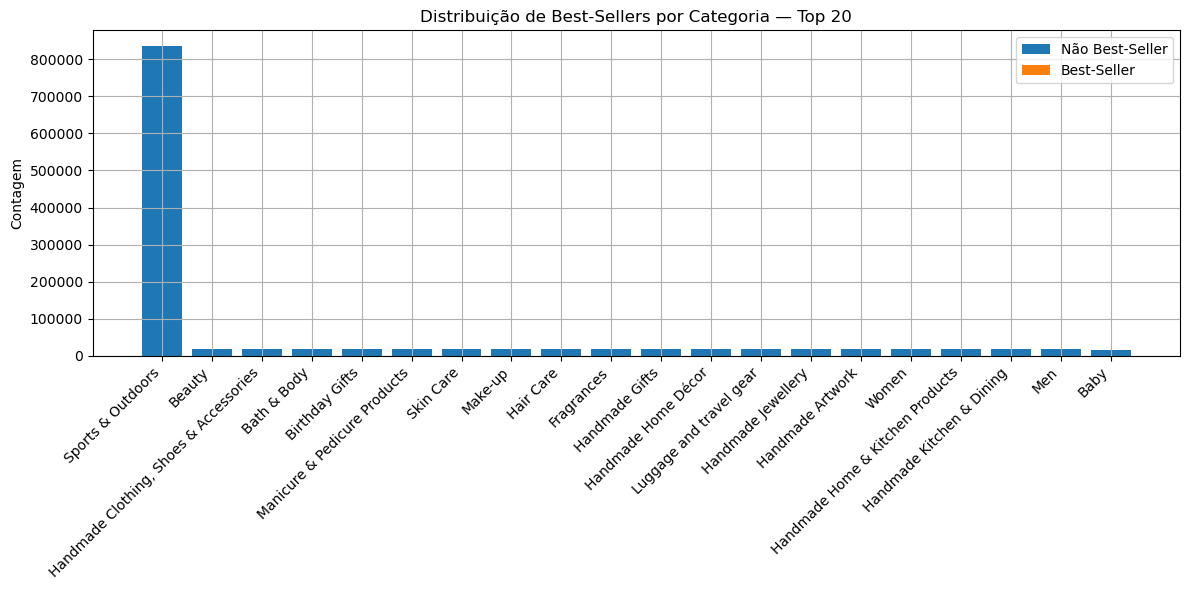

In [8]:
# ===============================
# Parte 1 — Best-Seller × Categoria
# ===============================

# 1) Tabela cruzada (contagens e proporções)
ct_counts = pd.crosstab(df[cat_col], df[best_col])
ct_props = ct_counts.div(ct_counts.sum(axis=1), axis=0)

print("Crosstab (contagens):")
display(ct_counts.head())

print("Crosstab (proporções):")
display(ct_props.head())

# Top categorias com maior proporção de best-sellers
if True in ct_props.columns:
    top_best = ct_props[True].sort_values(ascending=False)
    print("\nTop categorias por % de best-sellers:")
    display(top_best.head(20))

# 2) Teste Qui-quadrado + Cramér's V
from scipy.stats import chi2_contingency
chi2, p, dof, expected = chi2_contingency(ct_counts, correction=False)
n = ct_counts.to_numpy().sum()
min_dim = min(ct_counts.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else np.nan

print(f"Chi² = {chi2:.4f} | p = {p:.6f} | dof = {dof}")
print(f"Cramér's V = {cramers_v:.4f}")

# 3) Gráfico de barras empilhadas — AJUSTADO para Top N categorias
top_n = 20  # ajuste este valor se quiser ver mais/menos categorias
top_cats = df[cat_col].value_counts().head(top_n).index

ct_top = ct_counts.loc[top_cats]

cats = ct_top.index
vals_true = ct_top[True] if True in ct_top.columns else np.zeros(len(cats))
vals_false = ct_top[False] if False in ct_top.columns else np.zeros(len(cats))

idx = np.arange(len(cats))

plt.figure(figsize=(12,6))
plt.bar(idx, vals_false, label="Não Best-Seller")
plt.bar(idx, vals_true, bottom=vals_false, label="Best-Seller")
plt.xticks(idx, cats, rotation=45, ha="right")
plt.ylabel("Contagem")
plt.title(f"Distribuição de Best-Sellers por Categoria — Top {top_n}")
plt.legend()
plt.tight_layout()
plt.show()


Antes: 2443631 | Depois da remoção de outliers: 2115943


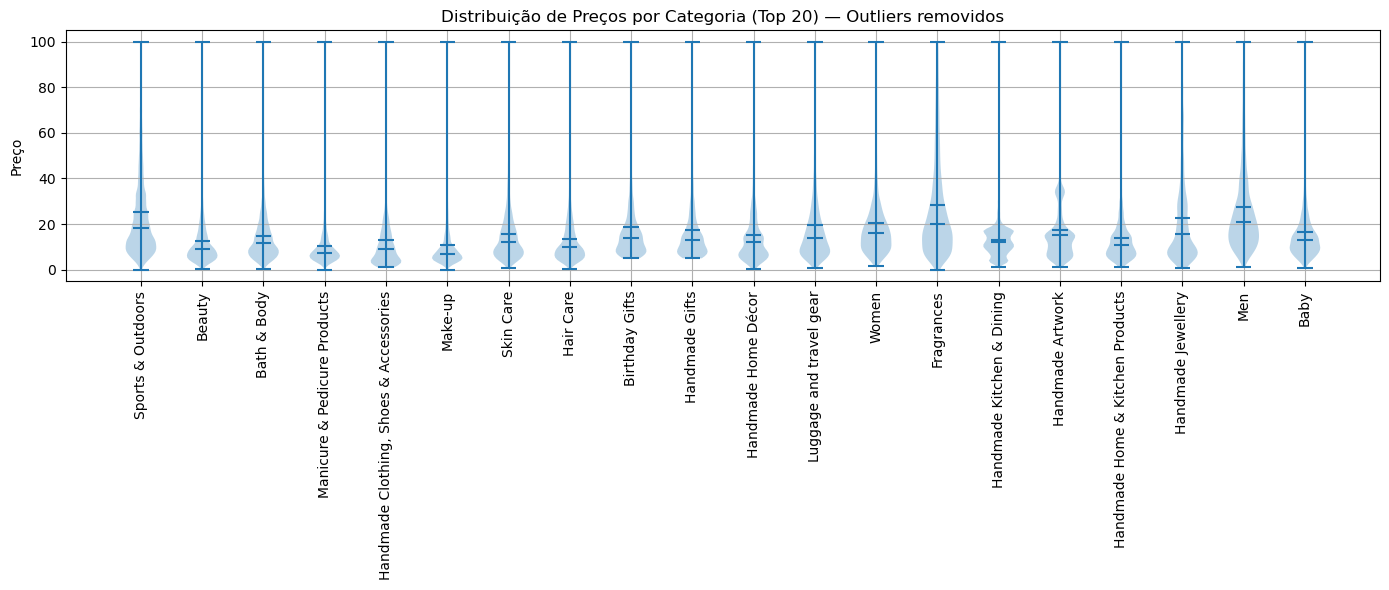

Categoria com maior mediana de preço: Desktop PCs


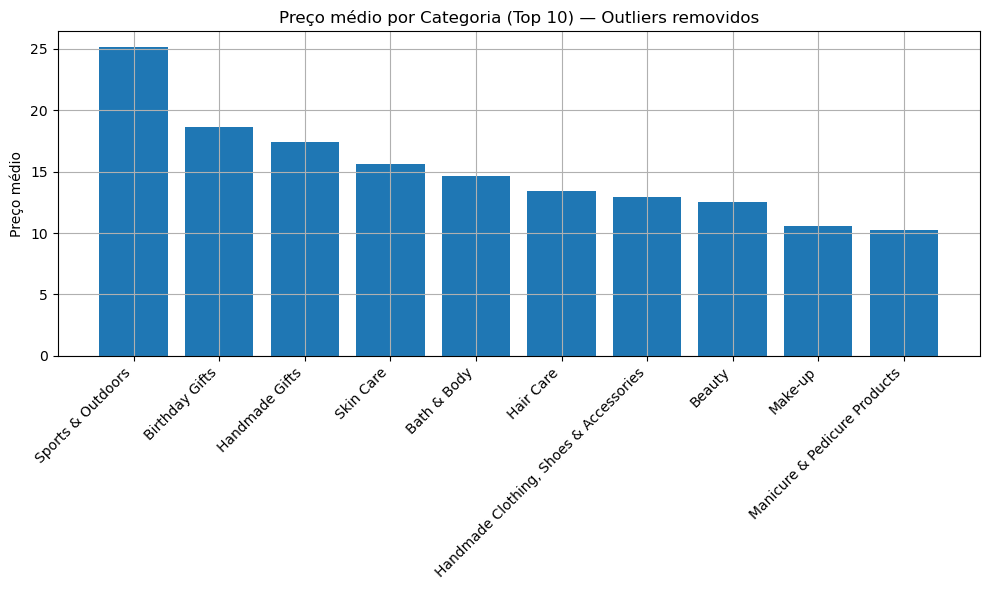

Categoria com maior média de preço: Motherboards


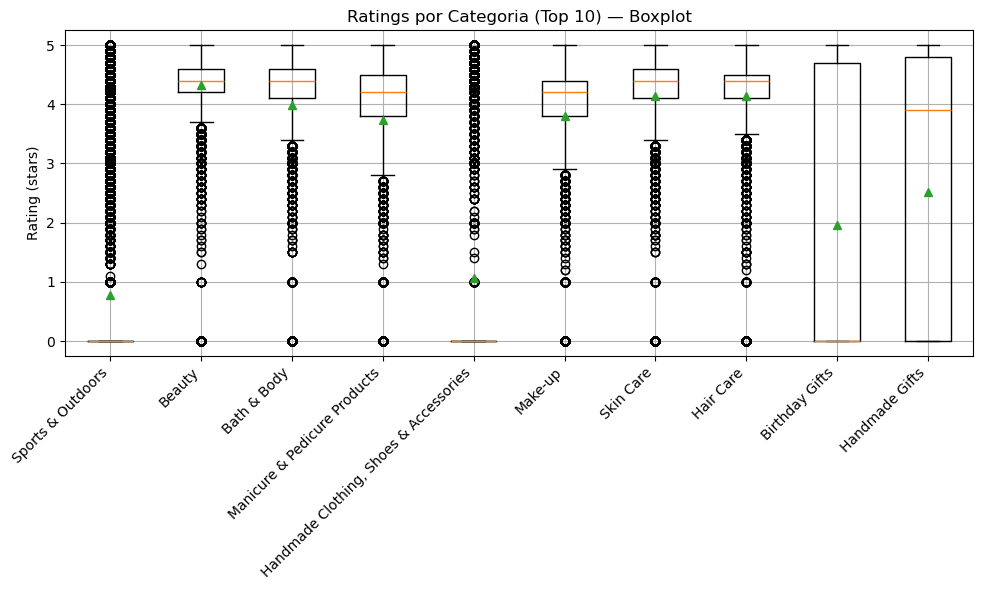

Categoria com maior mediana de rating: Computer Memory


In [3]:
# ===============================
# Parte 2 — Preços & Ratings por Categoria
# ===============================

# --- Remoção de outliers (IQR) ---
Q1 = df[price_col].quantile(0.25)
Q3 = df[price_col].quantile(0.75)
IQR = Q3 - Q1
low = Q1 - 1.5 * IQR
high = Q3 + 1.5 * IQR

df_no_out = df[(df[price_col] >= low) & (df[price_col] <= high)].copy()
print(f"Antes: {len(df)} | Depois da remoção de outliers: {len(df_no_out)}")

# --- Top categorias ---
cat_counts = df_no_out[cat_col].value_counts()
top20_cats = cat_counts.head(20).index
top10_cats = cat_counts.head(10).index

# Violin plot - preço por categoria (Top 20)
data = [df_no_out.loc[df_no_out[cat_col]==c, price_col] for c in top20_cats]

plt.figure(figsize=(14,6))
plt.violinplot(data, showmeans=True, showmedians=True)
plt.xticks(np.arange(1, len(top20_cats)+1), top20_cats, rotation=90)
plt.ylabel("Preço")
plt.title("Distribuição de Preços por Categoria (Top 20) — Outliers removidos")
plt.tight_layout()
plt.show()

# Categoria com maior mediana de preço (sem filtro)
med_by_cat = df_no_out.groupby(cat_col)[price_col].median().sort_values(ascending=False)
print("Categoria com maior mediana de preço:", med_by_cat.index[0])

# Bar chart - preço médio Top 10 categorias
mean_by_cat = df_no_out.groupby(cat_col)[price_col].mean()
top10_mean = mean_by_cat.loc[top10_cats].sort_values(ascending=False)

plt.figure(figsize=(10,6))
plt.bar(top10_mean.index, top10_mean.values)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Preço médio")
plt.title("Preço médio por Categoria (Top 10) — Outliers removidos")
plt.tight_layout()
plt.show()

# Categoria com maior média de preço (sem filtro)
print("Categoria com maior média de preço:", mean_by_cat.sort_values(ascending=False).index[0])

# Box plot - ratings por categoria (Top 10)
rating_data = [df_no_out.loc[df_no_out[cat_col]==c, stars_col] for c in top10_cats]

plt.figure(figsize=(10,6))
plt.boxplot(rating_data, labels=top10_cats, showmeans=True)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Rating (stars)")
plt.title("Ratings por Categoria (Top 10) — Boxplot")
plt.tight_layout()
plt.show()

# Categoria com maior mediana de rating (sem filtro)
med_rating_by_cat = df_no_out.groupby(cat_col)[stars_col].median().sort_values(ascending=False)
print("Categoria com maior mediana de rating:", med_rating_by_cat.index[0])


Correlação Pearson (price × stars): r = -0.0777, p = 0.000000


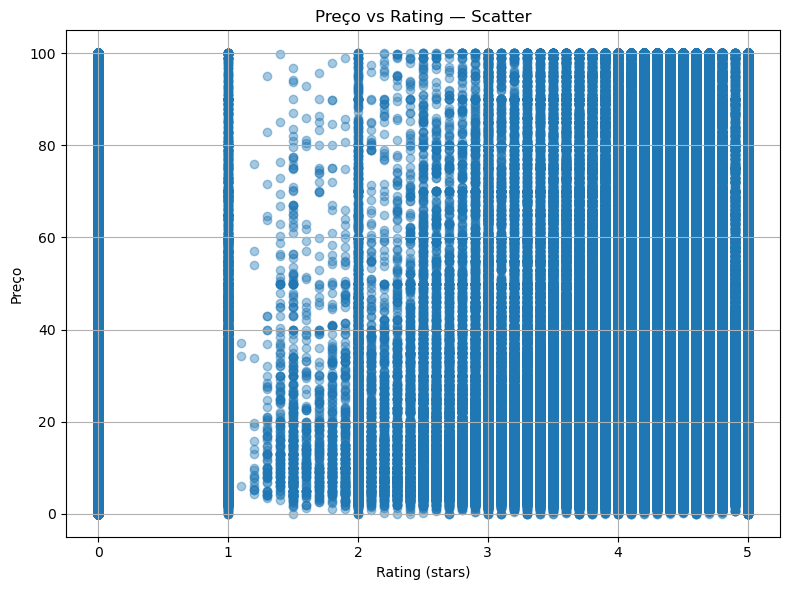

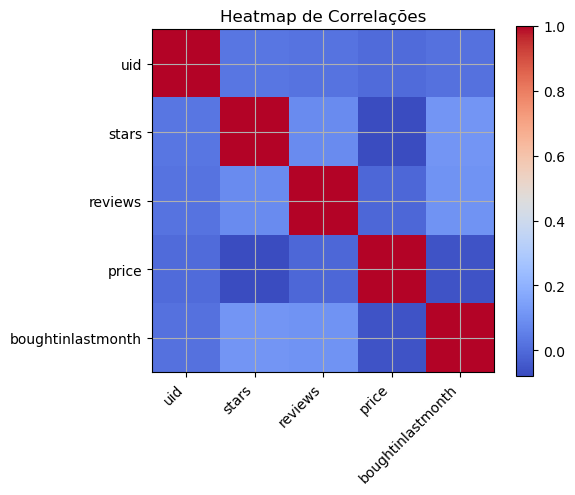

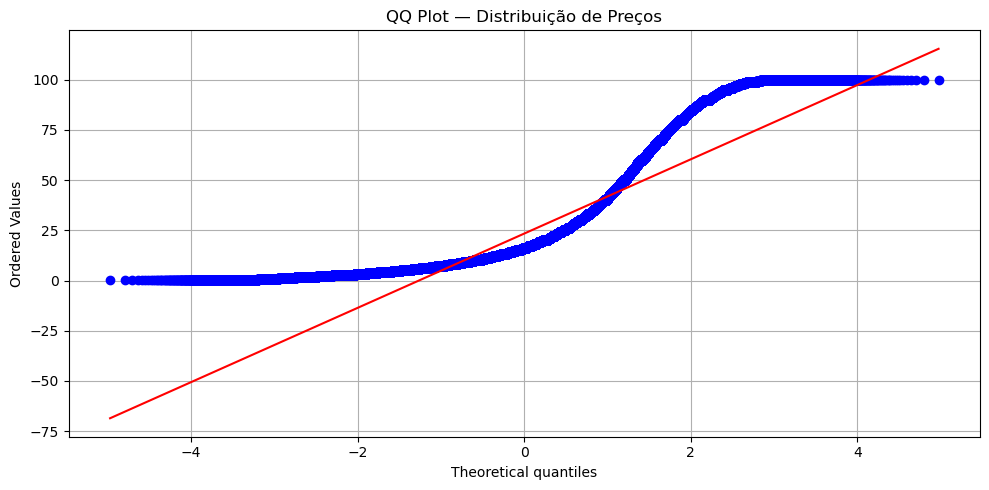

In [4]:
# ===============================
# Parte 3 — Correlação Preço × Rating
# ===============================

# Correlação
r, pval = pearsonr(df_no_out[price_col], df_no_out[stars_col])
print(f"Correlação Pearson (price × stars): r = {r:.4f}, p = {pval:.6f}")

# Scatter plot
plt.figure(figsize=(8,6))
plt.scatter(df_no_out[stars_col], df_no_out[price_col], alpha=0.4)
plt.xlabel("Rating (stars)")
plt.ylabel("Preço")
plt.title("Preço vs Rating — Scatter")
plt.tight_layout()
plt.show()

# Heatmap simples de correlações numéricas
num_df = df_no_out.select_dtypes(include=[np.number])
corr = num_df.corr()

plt.figure(figsize=(6,5))
plt.imshow(corr, cmap="coolwarm", interpolation="nearest")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
plt.colorbar()
plt.title("Heatmap de Correlações")
plt.tight_layout()
plt.show()

# QQ plot para verificar normalidade do preço
plt.figure()
probplot(df_no_out[price_col], dist="norm", plot=plt)
plt.title("QQ Plot — Distribuição de Preços")
plt.tight_layout()
plt.show()


In [5]:
# ===============================
# BÔNUS — Sem remover outliers
# ===============================

# Categoria com maior mediana e média de preço sem remoção
print("Maior mediana (com outliers):", df.groupby(cat_col)[price_col].median().sort_values(ascending=False).index[0])
print("Maior média (com outliers):", df.groupby(cat_col)[price_col].mean().sort_values(ascending=False).index[0])

# Correlação com outliers
r_all, p_all = pearsonr(df[price_col], df[stars_col])
print(f"Correlação com outliers: r = {r_all:.4f}, p = {p_all:.6f}")


Maior mediana (com outliers): Laptops
Maior média (com outliers): Laptops
Correlação com outliers: r = -0.1249, p = 0.000000
